# Анализ и прогнозирование оттока клиентов

В этом проекте я анализирую отток клиентов телеком-компании и пробую построить модель, которая сможет заранее выделять клиентов с повышенным риском ухода.

Сначала посмотрю на основные зависимости в данных, затем сравню две модели — логистическую регрессию и случайный лес.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    precision_recall_curve
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

## Загрузка данных

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Размер датасета:", df.shape)
df.info()

Размер датасета: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilli

В `TotalCharges` есть пустые значения, из-за которых столбец читается как текст.  
Переведу его в числовой формат. Пустые значения относятся к клиентам с нулевым стажем, поэтому заменю их на 0.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Пропусков в TotalCharges:", df["TotalCharges"].isna().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

Пропусков в TotalCharges: 11


## Общая доля оттока

In [5]:
churn_rate = df["ChurnFlag"].mean()

print(f"Доля клиентов, которые ушли: {churn_rate:.1%}")

Доля клиентов, которые ушли: 26.5%


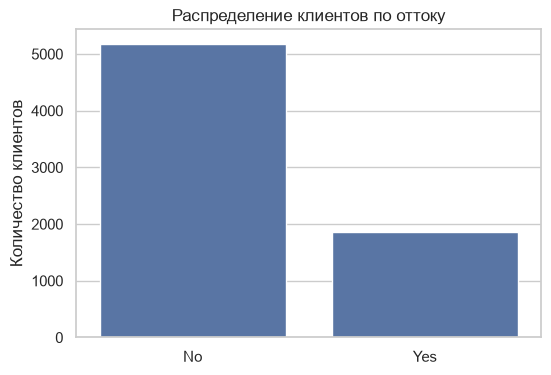

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Распределение клиентов по оттоку")
plt.xlabel("")
plt.ylabel("Количество клиентов")
plt.show()

Классы несбалансированы: ушедших клиентов заметно меньше, чем оставшихся.  
Поэтому дальше я не буду ориентироваться только на accuracy — для такой задачи важнее смотреть на ROC-AUC, precision и recall.

## Отток среди пожилых клиентов

In [7]:
senior_churn = (
    df.groupby("SeniorCitizen")["ChurnFlag"]
      .mean()
      .rename(index={0: "Нет", 1: "Да"})
)

senior_churn

SeniorCitizen
Нет    0.236062
Да     0.416813
Name: ChurnFlag, dtype: float64

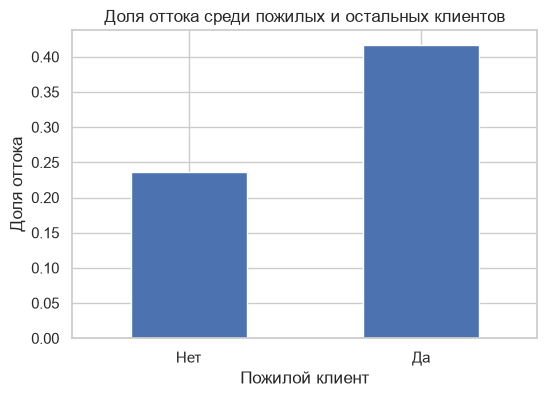

In [8]:
plt.figure(figsize=(6, 4))
senior_churn.plot(kind="bar")
plt.title("Доля оттока среди пожилых и остальных клиентов")
plt.xlabel("Пожилой клиент")
plt.ylabel("Доля оттока")
plt.xticks(rotation=0)
plt.show()

В этой выборке пожилые клиенты уходят чаще. Сам по себе возраст, конечно, не объясняет причину ухода, но может быть полезным признаком вместе с остальными характеристиками.

## Тип контракта

In [9]:
contract_churn = (
    df.groupby("Contract")["ChurnFlag"]
      .mean()
      .sort_values(ascending=False)
)

contract_churn

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: ChurnFlag, dtype: float64

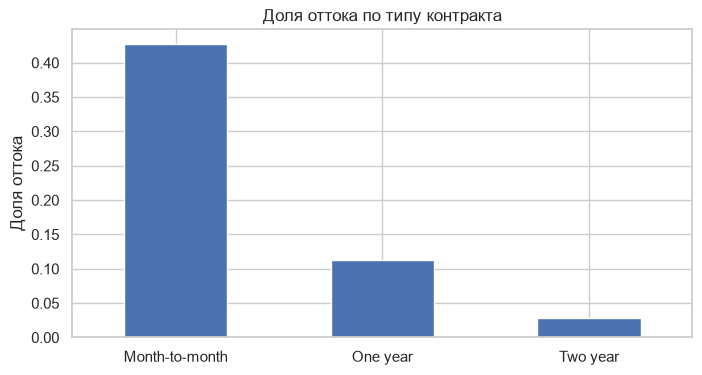

In [10]:
plt.figure(figsize=(8, 4))
contract_churn.plot(kind="bar")
plt.title("Доля оттока по типу контракта")
plt.xlabel("")
plt.ylabel("Доля оттока")
plt.xticks(rotation=0)
plt.show()

Сильнее всего выделяются клиенты с помесячным контрактом — среди них отток намного выше, чем среди клиентов с годовыми и двухлетними контрактами.

## Интернет-услуга

In [11]:
internet_churn = (
    df.groupby("InternetService")["ChurnFlag"]
      .mean()
      .sort_values(ascending=False)
)

internet_churn

InternetService
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: ChurnFlag, dtype: float64

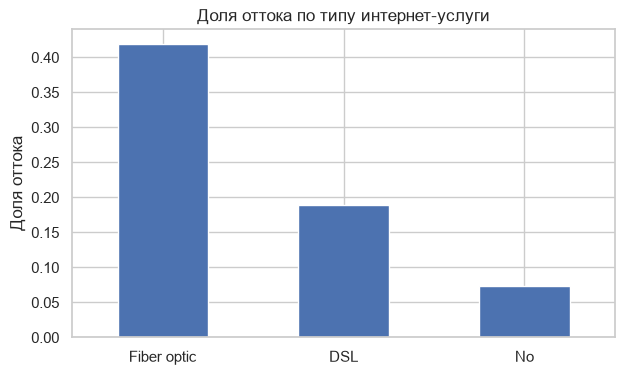

In [12]:
plt.figure(figsize=(7, 4))
internet_churn.plot(kind="bar")
plt.title("Доля оттока по типу интернет-услуги")
plt.xlabel("")
plt.ylabel("Доля оттока")
plt.xticks(rotation=0)
plt.show()

В этой выборке у клиентов с Fiber optic отток выше, чем у пользователей DSL.

## Количество подключённых дополнительных услуг

In [13]:
service_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["NumServices"] = (df[service_cols] == "Yes").sum(axis=1)

internet_customers = df[df["InternetService"] != "No"].copy()

services_churn = (
    internet_customers.groupby("NumServices")["ChurnFlag"]
      .agg(["mean", "count"])
      .rename(columns={"mean": "churn_rate", "count": "customers"})
)

services_churn

,churn_rate,customers
NumServices,,
0,0.522367,693
1,0.457557,966
2,0.358180,1033
3,0.273703,1118
4,0.223005,852
5,0.124343,571
6,0.052817,284


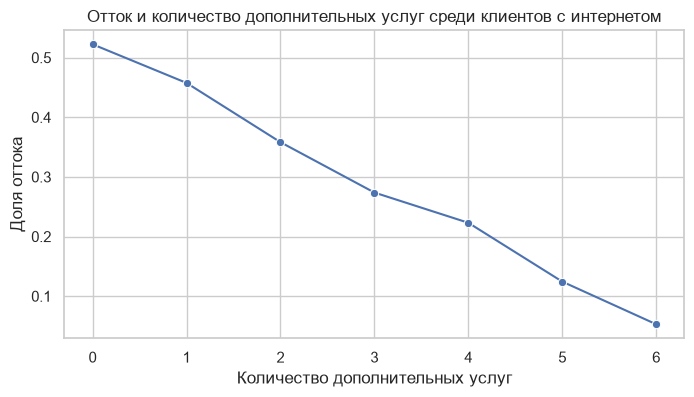

In [14]:
plt.figure(figsize=(8, 4))
sns.lineplot(
    x=services_churn.index,
    y=services_churn["churn_rate"],
    marker="o"
)
plt.title("Отток и количество дополнительных услуг среди клиентов с интернетом")
plt.xlabel("Количество дополнительных услуг")
plt.ylabel("Доля оттока")
plt.show()

Если считать всех клиентов вместе, группа с нулём дополнительных услуг получается неоднородной: туда попадают и пользователи интернета без дополнительных услуг, и клиенты, у которых интернета вообще нет. У второй группы отток заметно ниже, поэтому общий график искажает картину.

Если оставить только клиентов с интернетом, зависимость становится понятнее: при увеличении количества подключённых дополнительных услуг отток в целом снижается. В этой выборке он составляет примерно 52% у клиентов без дополнительных интернет-услуг и около 5% у клиентов со всеми шестью услугами.

Теперь перейду от описательного анализа к прогнозированию.

## Подготовка данных для моделей

`customerID` удаляю: это просто идентификатор клиента, полезной информации для прогноза он не несёт.

Данные делю на три части:

- train — обучение;
- validation — сравнение моделей и выбор порога;
- test — финальная проверка.

Разбиение делаю со `stratify`, чтобы доля оттока была примерно одинаковой во всех трёх выборках.

In [15]:
X = df.drop(columns=["customerID", "Churn", "ChurnFlag"])
y = df["ChurnFlag"]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=RANDOM_STATE
)

validation_share = 0.15 / 0.85

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=validation_share,
    stratify=y_train_val,
    random_state=RANDOM_STATE
)

pd.DataFrame({
    "Выборка": ["train", "validation", "test"],
    "Количество строк": [len(X_train), len(X_val), len(X_test)],
    "Доля оттока": [y_train.mean(), y_val.mean(), y_test.mean()]
})

,Выборка,Количество строк,Доля оттока
0,train,4929,0.265368
1,validation,1057,0.265847
2,test,1057,0.264901


## Preprocessing

In [16]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumServices"
]

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        numeric_features
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
        categorical_features
    )
])

Preprocessing помещаю внутрь `Pipeline`, чтобы масштабирование и кодирование категорий обучались только на train и не было утечки данных.

## Логистическая регрессия

In [17]:
logreg = Pipeline([
    ("preprocess", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
])

logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'NumServices']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

## Случайный лес

In [18]:
rf = Pipeline([
    ("preprocess", preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=10,
            min_samples_leaf=4,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'NumServices']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

## Сравнение моделей

In [19]:
def get_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions)
    }


models = {
    "Logistic Regression": logreg,
    "Random Forest": rf
}

validation_results = []
validation_probabilities = {}

for name, model in models.items():
    probs = model.predict_proba(X_val)[:, 1]
    validation_probabilities[name] = probs

    row = {"Model": name}
    row.update(get_metrics(y_val, probs))
    validation_results.append(row)

validation_results = pd.DataFrame(validation_results)
validation_results

,Model,ROC-AUC,Precision,Recall,F1
0,Logistic Regression,0.829149,0.510638,0.768683,0.613636
1,Random Forest,0.835207,0.530713,0.768683,0.627907


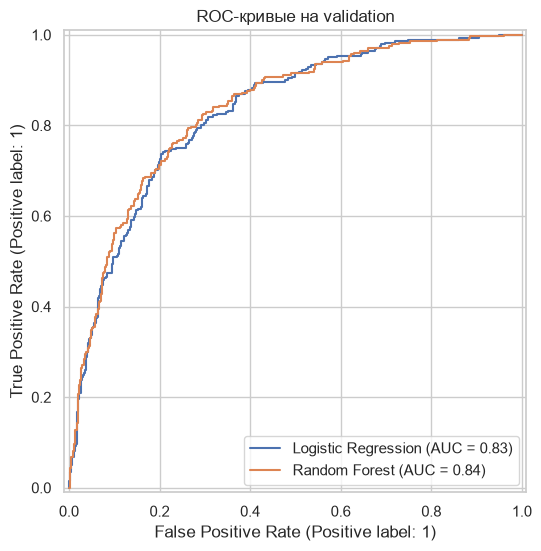

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, probs in validation_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_val,
        probs,
        name=name,
        ax=ax
    )

plt.title("ROC-кривые на validation")
plt.show()

ROC-AUC показывает, насколько хорошо модель в целом ранжирует клиентов по риску оттока.

Но для реальной retention-задачи важен ещё и порог: кого именно считать клиентом с высоким риском.

## Выбор порога

Стандартный порог 0.5 не обязательно лучший.

Если компании важнее не пропустить потенциально уходящих клиентов, можно немного снизить порог и повысить recall. Цена этого — больше ложных срабатываний.

Для примера выберу порог по F2-score на validation. F2 сильнее учитывает recall, чем precision.

In [21]:
def find_best_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    precision = precision[:-1]
    recall = recall[:-1]

    f2 = (
        5 * precision * recall
        / (4 * precision + recall + 1e-12)
    )

    best_idx = np.argmax(f2)

    return {
        "threshold": thresholds[best_idx],
        "precision": precision[best_idx],
        "recall": recall[best_idx],
        "f2": f2[best_idx]
    }


threshold_results = []

for name, probs in validation_probabilities.items():
    result = find_best_threshold(y_val, probs)
    result["Model"] = name
    threshold_results.append(result)

threshold_results = pd.DataFrame(threshold_results)
threshold_results

,threshold,precision,recall,f2,Model
0,0.331280,0.440351,0.893238,0.74085,Logistic Regression
1,0.280724,0.431472,0.907473,0.74344,Random Forest


In [22]:
best_model_name = (
    validation_results
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_threshold = float(
    threshold_results.loc[
        threshold_results["Model"] == best_model_name,
        "threshold"
    ].iloc[0]
)

print("Выбранная модель:", best_model_name)
print("Выбранный порог:", round(best_threshold, 3))

Выбранная модель: Random Forest
Выбранный порог: 0.281


## Финальная проверка на test

In [23]:
test_results = []

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Threshold": 0.5
    }
    row.update(get_metrics(y_test, probs, threshold=0.5))
    test_results.append(row)

best_model = models[best_model_name]
best_test_probs = best_model.predict_proba(X_test)[:, 1]

row = {
    "Model": f"{best_model_name} + выбранный порог",
    "Threshold": best_threshold
}
row.update(
    get_metrics(
        y_test,
        best_test_probs,
        threshold=best_threshold
    )
)

test_results.append(row)

test_results = pd.DataFrame(test_results)
test_results

,Model,Threshold,ROC-AUC,Precision,Recall,F1
0,Logistic Regression,0.500000,0.849134,0.507830,0.810714,0.624484
1,Random Forest,0.500000,0.847525,0.536408,0.789286,0.638728
2,Random Forest + выбранный порог,0.280724,0.847525,0.423394,0.917857,0.579481


### Результаты моделей

На validation случайный лес показал ROC-AUC около **0,835**, логистическая регрессия — около **0,829**. Поэтому модель и порог выбирались по validation, и дальше использовался Random Forest.

На test разница между моделями практически исчезла: ROC-AUC около **0,848** у Random Forest и **0,849** у Logistic Regression. Поэтому говорить, что случайный лес однозначно лучше, нельзя — обе модели дают примерно одинаковое качество ранжирования.

Для Random Forest порог, выбранный на validation по F2-score, получился около **0,276**. При таком пороге на test:

- найдено **258 из 280** реально ушедших клиентов — recall около **92%**;
- модель пометила как риск оттока **613 из 1 057** клиентов;
- precision составил около **42%**.

То есть модель хорошо подходит для **приоритизации клиентов**, если компании важнее не пропустить потенциальный отток. Но использовать её как точный ответ «уйдёт / не уйдёт» нельзя: при высоком recall получается много ложных срабатываний.

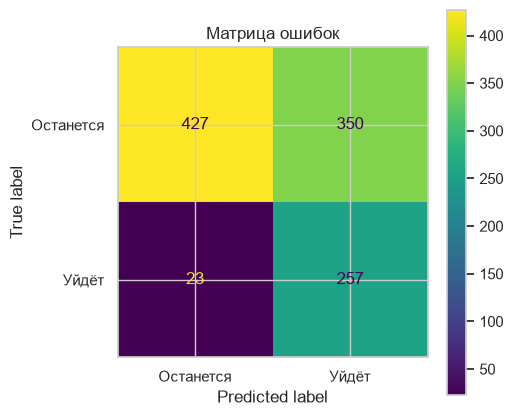

In [24]:
best_test_pred = (
    best_test_probs >= best_threshold
).astype(int)

fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, best_test_pred),
    display_labels=["Останется", "Уйдёт"]
).plot(ax=ax, values_format="d")

plt.title("Матрица ошибок")
plt.show()

Матрица ошибок показывает компромисс выбранного порога. False negative здесь особенно важны: это клиенты, которые реально ушли, но модель не выделила их заранее.

При пороге 0,276 таких клиентов осталось относительно мало, но за высокий recall приходится платить большим количеством false positive — клиентов, которых retention-команда обработает зря.

## Какие признаки сильнее всего влияют на прогноз

### Коэффициенты логистической регрессии

In [25]:
feature_names = (
    logreg
    .named_steps["preprocess"]
    .get_feature_names_out()
)

coefficients = (
    logreg
    .named_steps["model"]
    .coef_[0]
)

logreg_features = (
    pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefficients,
        "abs_coefficient": np.abs(coefficients)
    })
    .sort_values("abs_coefficient", ascending=False)
)

logreg_features.head(15)

,feature,coefficient,abs_coefficient
1,num__tenure,-1.162811,1.162811
35,cat__Contract_Two year,-0.829503,0.829503
33,cat__Contract_Month-to-month,0.689680,0.689680
12,cat__InternetService_DSL,-0.582008,0.582008
13,cat__InternetService_Fiber optic,0.556844,0.556844
3,num__TotalCharges,0.491214,0.491214
2,num__MonthlyCharges,-0.451243,0.451243
36,cat__PaperlessBilling_Yes,0.354100,0.354100
25,cat__TechSupport_No internet service,-0.240946,0.240946
22,cat__DeviceProtection_No internet service,-0.240946,0.240946


### Важность признаков Random Forest

In [26]:
rf_feature_names = (
    rf
    .named_steps["preprocess"]
    .get_feature_names_out()
)

rf_importance = (
    rf
    .named_steps["model"]
    .feature_importances_
)

rf_features = (
    pd.DataFrame({
        "feature": rf_feature_names,
        "importance": rf_importance
    })
    .sort_values("importance", ascending=False)
)

rf_features.head(15)

,feature,importance
33,cat__Contract_Month-to-month,0.148611
1,num__tenure,0.121225
3,num__TotalCharges,0.099990
2,num__MonthlyCharges,0.070491
35,cat__Contract_Two year,0.067075
15,cat__OnlineSecurity_No,0.056733
24,cat__TechSupport_No,0.052758
13,cat__InternetService_Fiber optic,0.047819
39,cat__PaymentMethod_Electronic check,0.036703
34,cat__Contract_One year,0.025572


Важно: высокая важность признака ещё не означает причинно-следственную связь.

Например, если помесячный контракт хорошо помогает прогнозировать отток, из этого нельзя автоматически делать вывод, что перевод клиента на годовой контракт сам по себе снизит вероятность ухода.

## Итог

В проекте я сначала посмотрел, какие группы клиентов чаще уходят, а затем построил две модели для прогноза оттока.

Что получилось сделать:

- подготовить данные и обработать `TotalCharges`;
- посмотреть отток по нескольким важным сегментам;
- отдельно разобрать влияние дополнительных услуг только среди клиентов с интернетом;
- построить Logistic Regression и Random Forest;
- сравнить модели по ROC-AUC, precision, recall и F1;
- подобрать порог на validation, не используя test для настройки;
- проверить итоговый результат на test;
- посмотреть коэффициенты Logistic Regression и feature importance Random Forest.

Обе модели показали ROC-AUC около **0,85** на test и практически не отличаются по качеству. При снижении порога до **0,276** Random Forest находит около **92%** ушедших клиентов, но precision падает примерно до **42%**.

Поэтому такой прогноз разумнее использовать не как окончательное решение, а для приоритизации retention-кампании. А эффективность конкретного предложения клиентам уже нужно проверять отдельно, например через A/B-тест.